# Analysing MIPI Failure Cases

## Setups and Imports

In [ ]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
from scipy import stats
import json

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)

## Retrieving & Augmenting Dataframe

In [2]:
dataset = "8h_deduplicated"
# dataset = "repairllama_deduplicated"

dataset_dir_name = "placeholder"
if dataset == "8h_deduplicated":
    dataset_dir_name = "petke_8h"
elif dataset == "repairllama_deduplicated":
    dataset_dir_name = "repairllama_dedup"

FIGURES_DIR = Path("mipi_failure_figures") / dataset_dir_name
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df_total_classified_patches_llm4patchcorrect = pd.read_csv(
    Path(f"../results/LLM4PatchCorrectness/{dataset}.csv"))
df_mipi_classified_patches = pd.read_csv(
    Path(f"../results/mipi/{dataset}.csv"))
list_mipi_patches = df_mipi_classified_patches['patch_name'].tolist()

print("Total classified patches from LLM4PatchCorrectness:",
      len(df_total_classified_patches_llm4patchcorrect))
print("Total classified patches from MIPI:", len(df_mipi_classified_patches))

Total classified patches from LLM4PatchCorrectness: 819
Total classified patches from MIPI: 373


In [3]:
TOOL_NAME_MAP = {
    "avatar": "Avatar", "fixminer": "FixMiner", "nopol": "Nopol",
    "simfix": "SimFix", "tbar": "TBar", "dynamoth": "dynamoth",
    "jgenprog": "jGenProg", "jkali": "jKali",
    "jmutrepair": "jMutRepair", "kpar": "kPAR", "repairllama-ir4": "Repairllama"
}

df_all_patches = df_total_classified_patches_llm4patchcorrect[[
    'patch_name', 'correctness']].copy()
df_all_patches['project'] = df_all_patches['patch_name'].apply(
    lambda x: x.split('_')[0])
df_all_patches['bug_id'] = df_all_patches['patch_name'].apply(
    lambda x: x.split('_')[1])
df_all_patches['apr_tool'] = df_all_patches['patch_name'].apply(
    lambda x: TOOL_NAME_MAP.get(x.split('_')[2].lower(), x.split('_')[2])
)
df_all_patches['mipi_classified'] = df_all_patches['patch_name'].isin(
    list_mipi_patches)
df_all_patches['mipi_prediction'] = df_all_patches['patch_name'].apply(
    lambda x: df_mipi_classified_patches.loc[
        df_mipi_classified_patches['patch_name'] == x, 'prediction'
    ].values[0] if x in list_mipi_patches else None
)

# Load Defects4J bug metadata and merge
with open(Path('./defects4j-bugs.json'), encoding='utf-8') as f:
    bugs_raw = json.load(f)

df_bugs = pd.DataFrame([{
    'project': b['project'].lower(),
    'bug_id': str(b['bugId']),
    'repair_patterns': b.get('repairPatterns') or [],
    'dev_fix_lines_add': b['metrics']['linesAdd'],
    'dev_fix_lines_rem': b['metrics']['linesRem'],
    'dev_fix_lines_mod': b['metrics']['linesMod'],
    'dev_fix_n_files': b['metrics']['files'],
    'dev_fix_n_chunks': b['metrics']['chunks'],
    'first_exception': b['failingTests'][0]['error'].split(".")[-1] if b.get('failingTests') else None,
} for b in bugs_raw])

df_all_patches['_project_key'] = df_all_patches['project'].str.lower()
df_all_patches = df_all_patches.merge(
    df_bugs,
    left_on=['_project_key', 'bug_id'],
    right_on=['project', 'bug_id'],
    how='left',
    suffixes=('', '_bug'),
).drop(columns=['project_bug', '_project_key'])

df_all_patches['dev_fix_size_in_lines'] = (
    df_all_patches['dev_fix_lines_add']
    + df_all_patches['dev_fix_lines_rem']
    + 2 * df_all_patches['dev_fix_lines_mod']
)

PATCH_DIRS = {
    '8h_deduplicated': {
        'correct': Path('../datasets/petke/patches_by_time/patches_8h_deduplicated/correct'),
        'overfitting': Path('../datasets/petke/patches_by_time/patches_8h_deduplicated/overfitting'),
    },
    'repairllama_deduplicated': {
        'correct': Path('../datasets/repairllama/context_size_3_filtered/correct'),
        'overfitting': Path('../datasets/repairllama/context_size_3_filtered/overfitting'),
    },
}


def count_patch_lines(row):
    correctness = str(row['correctness']).lower()
    patch_path = PATCH_DIRS[dataset][correctness] / row['patch_name']
    if not patch_path.is_file():
        raise FileNotFoundError(f'Patch file not found: {patch_path}')

    added_lines = 0
    removed_lines = 0
    for line in patch_path.read_text(encoding='utf-8').splitlines():
        if line.startswith('+++') or line.startswith('---'):
            continue
        added_lines += line.startswith('+')
        removed_lines += line.startswith('-')

    return pd.Series({
        'patch_added_lines': added_lines,
        'patch_removed_lines': removed_lines,
    })


df_all_patches[['patch_added_lines', 'patch_removed_lines']] = df_all_patches.apply(
    count_patch_lines, axis=1
)

df_all_patches["patch_total_lines"] = (
    df_all_patches["patch_added_lines"]
    + df_all_patches["patch_removed_lines"]
)

df_all_patches["patch_net_change"] = (
    df_all_patches["patch_added_lines"]
    - df_all_patches["patch_removed_lines"]
)

df_all_patches["deviation_from_dev_patch"] = (
    df_all_patches["patch_total_lines"]
    - df_all_patches["dev_fix_size_in_lines"]
)

matched = df_all_patches['dev_fix_size_in_lines'].notna().sum()
print(
    f"Patches matched to Defects4J bug metadata: {matched}/{len(df_all_patches)} ({matched/len(df_all_patches)*100:.1f}%)")
print(df_all_patches.columns.tolist())
df_all_patches.head()

Patches matched to Defects4J bug metadata: 819/819 (100.0%)
['patch_name', 'correctness', 'project', 'bug_id', 'apr_tool', 'mipi_classified', 'mipi_prediction', 'repair_patterns', 'dev_fix_lines_add', 'dev_fix_lines_rem', 'dev_fix_lines_mod', 'dev_fix_n_files', 'dev_fix_n_chunks', 'first_exception', 'dev_fix_size_in_lines', 'patch_added_lines', 'patch_removed_lines', 'patch_total_lines', 'patch_net_change', 'deviation_from_dev_patch']


,patch_name,correctness,project,bug_id,apr_tool,mipi_classified,mipi_prediction,repair_patterns,dev_fix_lines_add,dev_fix_lines_rem,dev_fix_lines_mod,dev_fix_n_files,dev_fix_n_chunks,first_exception,dev_fix_size_in_lines,patch_added_lines,patch_removed_lines,patch_total_lines,patch_net_change,deviation_from_dev_patch
0,Math_6_SimFix_patch_97949_1.diff,overfitting,Math,6,SimFix,False,None,"[constChange, copyPaste, expLogicMod, initFix, wrongComp, wrongVarRef]",2,4,12,7,17,AssertionFailedError,30,5,0,5,5,-25
1,Math_80_jGenProg_patch_3653000_3640.diff,overfitting,Math,80,jGenProg,False,None,"[expArithMod, singleLine]",0,0,1,1,1,AssertionFailedError,2,1,1,2,0,0
2,Closure_126_jKali_patch_12000_4.diff,overfitting,Closure,126,jKali,False,None,[condBlockRem],0,4,0,1,1,AssertionFailedError,4,2,2,4,0,0
3,Math_82_TBar_Patch_12384523_2382_cp1069.diff,overfitting,Math,82,TBar,True,correct,"[expLogicMod, singleLine]",0,0,1,1,1,AssertionFailedError,2,1,1,2,0,0
4,Math_50_SimFix_patch_1472629_6.diff,overfitting,Math,50,SimFix,False,None,[condBlockRem],0,4,0,1,1,AssertionFailedError,4,8,0,8,8,4


In [4]:
def patch_shape(row):
    added = row["patch_added_lines"]
    removed = row["patch_removed_lines"]

    if added == 0 and removed == 0:
        return "empty"
    if added == 0:
        return "deletion-only"
    if removed == 0:
        return "addition-only"
    if added == removed:
        return "balanced"
    return "addition-heavy" if added > removed else "deletion-heavy"

df_all_patches["patch_shape"] = df_all_patches.apply(patch_shape, axis=1)

df_all_patches.groupby("patch_shape")["mipi_classified"].agg(
    total="count",
    classified="sum"
).assign(
    failure_rate=lambda x: 1 - x["classified"] / x["total"]
)

,total,classified,failure_rate
patch_shape,,,
addition-heavy,150,92,0.386667
addition-only,51,0,1.000000
balanced,482,215,0.553942
deletion-heavy,133,66,0.503759
deletion-only,3,0,1.000000


In [5]:
df_all_patches["patch_size_bin"] = pd.cut(
    df_all_patches["patch_total_lines"],
    bins=[-1, 1, 3, 10, 25, 50, np.inf],
    labels=["0-1", "2-3", "4-10", "11-25", "26-50", "50+"]
)

df_all_patches.groupby("patch_size_bin")["mipi_classified"].agg(
    total="count",
    classified="sum"
).assign(
    failure_rate=lambda x: 1 - x["classified"] / x["total"]
)

C:\Users\Dave\AppData\Local\Temp\ipykernel_6204\2928478128.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_all_patches.groupby("patch_size_bin")["mipi_classified"].agg(


,total,classified,failure_rate
patch_size_bin,,,
0-1,3,0,1.000000
2-3,423,202,0.522459
4-10,266,104,0.609023
11-25,39,10,0.743590
26-50,51,36,0.294118
50+,37,21,0.432432


In [6]:
df_all_patches.groupby(["patch_shape", "apr_tool"])["mipi_classified"].agg(
    total="count",
    classified="sum"
).assign(
    failure_rate=lambda x: 1 - x["classified"] / x["total"]
)

total  classified  failure_rate
patch_shape    apr_tool                                   
addition-heavy Avatar         12           9      0.250000
               FixMiner        6           2      0.666667
               Nopol          38          12      0.684211
               TBar           24          15      0.375000
               dynamoth       60          51      0.150000
               jGenProg        5           0      1.000000
               jKali           1           1      0.000000
               kPAR            4           2      0.500000
addition-only  SimFix         51           0      1.000000
balanced       Avatar         43          26      0.395349
               FixMiner       22          15      0.318182
               Nopol          17           3      0.823529
               TBar          161          94      0.416149
               dynamoth       10           4      0.600000
               jGenProg       75          36      0.520000
               jKali          40           7      0.825000
               jMutRepair     24          12      0.500000
               kPAR           90          18      0.800000
deletion-heavy Avatar         77          54      0.298701
               FixMiner        8           3      0.625000
               Nopol           2           0      1.000000
               TBar           25           8      0.680000
               dynamoth        2           0      1.000000
               kPAR           19           1      0.947368
deletion-only  Avatar          1           0      1.000000
               TBar            1           0      1.000000
               kPAR            1           0      1.000000

## Overall MIPI Failure Rate

In [7]:
total = len(df_all_patches)
n_classified = df_all_patches['mipi_classified'].sum()
n_failed = total - n_classified

print(f"Total patches:           {total}")
print(f"MIPI classified:         {n_classified} ({n_classified/total*100:.1f}%)")
print(f"MIPI failed to classify: {n_failed} ({n_failed/total*100:.1f}%)")

Total patches:           819
MIPI classified:         373 (45.5%)
MIPI failed to classify: 446 (54.5%)


## Failure Rate Per Bug

In [8]:
# MIPI successful classification rate per project and bug ID
df_failure_per_bug =df_all_patches.groupby(['project', 'bug_id'])['mipi_classified'].mean().to_frame()
df_failure_per_bug.head(10)

mipi_classified
project bug_id                 
Chart   1              0.896552
        11             1.000000
        12             0.000000
        13             1.000000
        15             0.250000
        17             1.000000
        18             0.000000
        20             0.000000
        24             1.000000
        25             0.769231

Number of completely classified bugs: 21
Completely classified bugs: [('Chart', '11'), ('Chart', '13'), ('Chart', '17'), ('Chart', '24'), ('Closure', '10'), ('Closure', '129'), ('Lang', '55'), ('Lang', '57'), ('Lang', '59'), ('Math', '105'), ('Math', '11'), ('Math', '20'), ('Math', '34'), ('Math', '49'), ('Math', '65'), ('Math', '69'), ('Math', '71'), ('Math', '89'), ('Mockito', '29'), ('Mockito', '38'), ('Time', '11')]
Number of completely failed bugs: 43
Completely failed bugs: [('Chart', '12'), ('Chart', '18'), ('Chart', '20'), ('Chart', '26'), ('Chart', '4'), ('Chart', '5'), ('Chart', '8'), ('Closure', '115'), ('Closure', '13'), ('Closure', '14'), ('Closure', '19'), ('Closure', '2'), ('Closure', '21'), ('Closure', '22'), ('Closure', '48'), ('Closure', '57'), ('Closure', '62'), ('Closure', '73'), ('Closure', '86'), ('Lang', '44'), ('Lang', '45'), ('Lang', '46'), ('Lang', '51'), ('Lang', '58'), ('Lang', '6'), ('Math', '101'), ('Math', '15'), ('Math', '28'), ('Math', '30'), ('Math', '

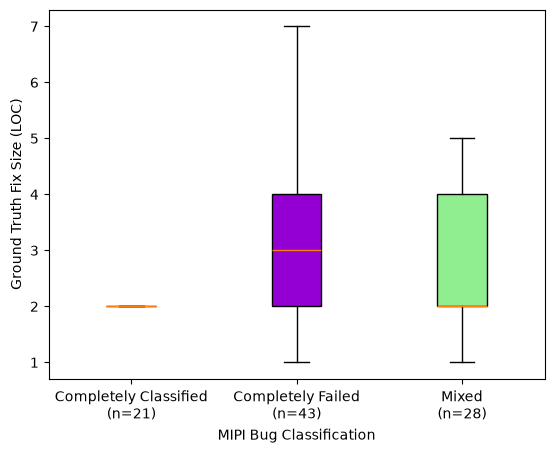

In [9]:
num_completely_classified_bugs = (df_failure_per_bug['mipi_classified'] == 1).sum()
completely_classified_bugs = df_failure_per_bug[df_failure_per_bug['mipi_classified'] == 1].index.tolist()
completely_failed_bugs = df_failure_per_bug[df_failure_per_bug['mipi_classified'] == 0].index.tolist()
num_completely_failed_bugs = (df_failure_per_bug['mipi_classified'] == 0).sum()
num_mixed_bugs = ((df_failure_per_bug['mipi_classified'] > 0) & (df_failure_per_bug['mipi_classified'] < 1)).sum()
mixed_bugs = df_failure_per_bug[(df_failure_per_bug['mipi_classified'] > 0) & (df_failure_per_bug['mipi_classified'] < 1)].index.tolist()

print("Number of completely classified bugs:", num_completely_classified_bugs)
print("Completely classified bugs:", completely_classified_bugs)
print("Number of completely failed bugs:", num_completely_failed_bugs)
print("Completely failed bugs:", completely_failed_bugs)
print("Number of mixed bugs:", num_mixed_bugs)
print("Mixed bugs:", mixed_bugs)

# Comparison box plot of ground truth fix size for the group of completely classified, completely failed, and mixed bugs

# df_all_patches has columns project and bug_id, whereas the list of completely classified, completely failed, and mixed bugs contains tuples of (project, bug_id)
data_to_plot = [
    df_all_patches[df_all_patches.set_index(['project', 'bug_id']).index.isin(completely_classified_bugs)]['dev_fix_size_in_lines'],
    df_all_patches[df_all_patches.set_index(['project', 'bug_id']).index.isin(completely_failed_bugs)]['dev_fix_size_in_lines'],
    df_all_patches[df_all_patches.set_index(['project', 'bug_id']).index.isin(mixed_bugs)]['dev_fix_size_in_lines'],
]

fig, ax = plt.subplots()
bp = ax.boxplot(data_to_plot, showfliers=False, patch_artist=True)
ax.set_xticklabels([f'Completely Classified\n(n={num_completely_classified_bugs})', f'Completely Failed\n(n={num_completely_failed_bugs})', f'Mixed\n(n={num_mixed_bugs})'])
ax.set_ylabel('Ground Truth Fix Size (LOC)')
bp['boxes'][0].set_facecolor('gold')
bp['boxes'][1].set_facecolor('darkviolet')
bp['boxes'][2].set_facecolor('lightgreen')

plt.xlabel('MIPI Bug Classification')
plt.savefig(FIGURES_DIR / "mipi_failure_bug_level_comparison_box_plot.png")
plt.show()

In [10]:
bug_counts_by_project = (
    df_all_patches.groupby("project")["bug_id"]
    .nunique()
    .sort_index()
    .rename("number_of_bugs")
)

display(bug_counts_by_project)

project
Chart      16
Closure    16
Lang       13
Math       43
Mockito     2
Time        2
Name: number_of_bugs, dtype: int64

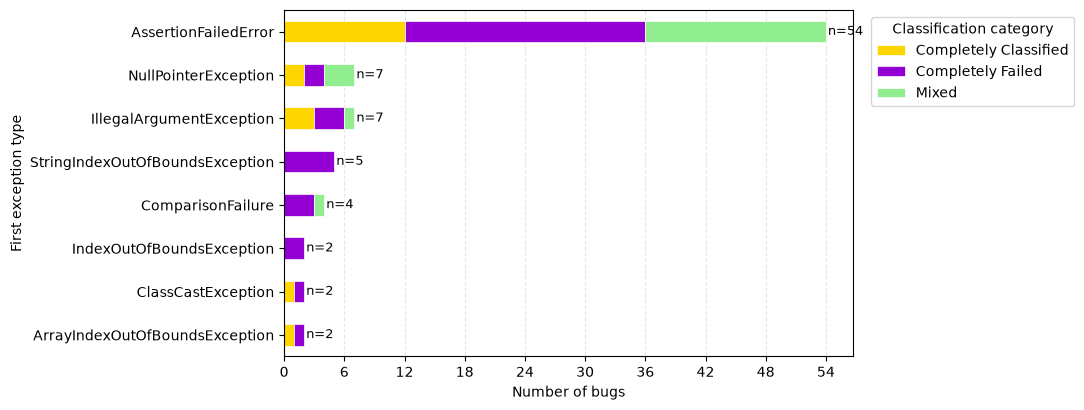

In [11]:
# Build one row per bug with its classification category.
bug_classification = df_failure_per_bug.reset_index()

bug_classification["classification"] = np.select(
    [
        bug_classification["mipi_classified"].eq(1),
        bug_classification["mipi_classified"].eq(0),
        bug_classification["mipi_classified"].between(0, 1, inclusive="neither"),
    ],
    [
        "Completely Classified",
        "Completely Failed",
        "Mixed",
    ],
    default="Unknown",
)

# first_exception is repeated across patch rows, so retain one value per bug.
bug_exceptions = (
    df_all_patches
    .groupby(["project", "bug_id"], as_index=False)["first_exception"]
    .first()
)

bug_exceptions["first_exception"] = (
    bug_exceptions["first_exception"]
    .fillna("Unknown / unavailable")
)

bug_level = bug_classification.merge(
    bug_exceptions,
    on=["project", "bug_id"],
    how="left",
    validate="one_to_one",
)

classification_order = [
    "Completely Classified",
    "Completely Failed",
    "Mixed",
]

# Exclude very rare exception types to keep the figure readable.
MIN_BUGS_PER_EXCEPTION = 2

exception_counts = bug_level["first_exception"].value_counts()
exceptions_to_plot = exception_counts[
    exception_counts >= MIN_BUGS_PER_EXCEPTION
].index

plot_data = (
    bug_level[bug_level["first_exception"].isin(exceptions_to_plot)]
    .groupby(["first_exception", "classification"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=classification_order, fill_value=0)
)

plot_data["total"] = plot_data.sum(axis=1)
plot_data = plot_data.sort_values("total")

colors = {
    "Completely Classified": "gold",
    "Completely Failed": "darkviolet",
    "Mixed": "lightgreen",
}

fig, ax = plt.subplots(
    figsize=(11, max(4, 0.4 * len(plot_data) + 1))
)

plot_data[classification_order].plot(
    kind="barh",
    stacked=True,
    ax=ax,
    color=[colors[column] for column in classification_order],
    edgecolor="white",
    linewidth=0.5,
)

# Add the total number of bugs at the end of each bar.
for y_position, total in enumerate(plot_data["total"]):
    ax.text(
        total + 0.2,
        y_position,
        f"n={total}",
        va="center",
        fontsize=9,
    )

ax.set_xlabel("Number of bugs")
ax.set_ylabel("First exception type")
# ax.set_title("Bug Classification Category by Exception Type")
ax.legend(
    title="Classification category",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
)
ax.xaxis.set_major_locator(mtick.MaxNLocator(integer=True))
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
fig.savefig(
    FIGURES_DIR / f"mipi_bug_classification_by_exception_{dataset_dir_name}.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

In [12]:
df_all_patches[df_all_patches["first_exception"] == "StringIndexOutOfBoundsException"].groupby(["project", "bug_id"])["first_exception"].first()

project  bug_id
Lang     44        StringIndexOutOfBoundsException
         45        StringIndexOutOfBoundsException
         51        StringIndexOutOfBoundsException
         6         StringIndexOutOfBoundsException
Math     101       StringIndexOutOfBoundsException
Name: first_exception, dtype: object

## Failure Rate By Patch Correctness

In [13]:
# Failure rate by patch correctness
frequency_table = pd.crosstab(
    df_all_patches['correctness'],
    df_all_patches['mipi_classified'],
    margins=True,
    margins_name='Total'
).rename_axis(index='Correctness', columns='MIPI classified')
frequency_table

# print(frequency_table.to_latex(
#     caption='Frequencies of patch correctness by MIPI classification.',
#     label='tab:correctness-mipi-frequencies',
#     bold_rows=True
# ))

MIPI classified,False,True,Total
Correctness,,,
correct,68,61,129
overfitting,378,312,690
Total,446,373,819


## Failure Rate by Patch Dataframe Column

In [14]:
### Failure rate by column

def tool_failure_bar(df, col, color, title="", figsize=(8, 4), save_name=None):
    grp = (
        df.groupby(col)['mipi_classified']
        .agg(classified='sum', total='count')
        .reset_index()
    )
    grp['failed'] = grp['total'] - grp['classified']
    grp['failure_rate'] = grp['failed'] / grp['total'] * 100
    grp = grp.sort_values('failure_rate', ascending=False)

    contingency = pd.crosstab(df[col], df['mipi_classified'])
    chi2, p, dof, _ = stats.chi2_contingency(contingency)
    print(f"Chi-square test ({col}): χ²={chi2:.2f}, df={dof}, p={p:.10e}")

    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.bar(grp[col], grp['failure_rate'], color=color, edgecolor='white')
    ax.set_ylabel('MIPI Failure Rate (%)')
    ax.set_xlabel(col.replace('_', ' ').title())
    if title != "": ax.set_title(title)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_ylim(0, 115)
    for bar, row in zip(bars, grp.itertuples()):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
                f'{row.failure_rate:.0f}%\n(n={row.total})',
                ha='center', va='bottom', fontsize=8)
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    if save_name:
        fig.savefig(FIGURES_DIR / f"{save_name}_{dataset_dir_name}.png", dpi=300)
    plt.show()
    print(grp[[col, 'total', 'classified', 'failed', 'failure_rate']].to_string(index=False))
    return grp


### By APR Tool

Chi-square test (apr_tool): χ²=158.29, df=9, p=1.6821446949e-29


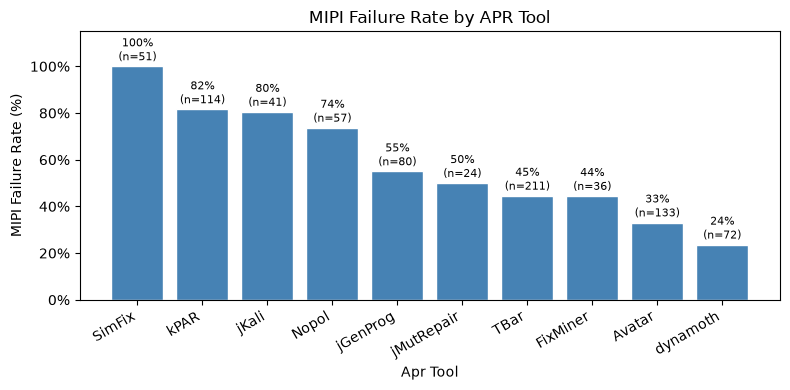

  apr_tool  total  classified  failed  failure_rate
    SimFix     51           0      51    100.000000
      kPAR    114          21      93     81.578947
     jKali     41           8      33     80.487805
     Nopol     57          15      42     73.684211
  jGenProg     80          36      44     55.000000
jMutRepair     24          12      12     50.000000
      TBar    211         117      94     44.549763
  FixMiner     36          20      16     44.444444
    Avatar    133          89      44     33.082707
  dynamoth     72          55      17     23.611111


In [15]:
# Failure rate by APR tool
tool_stats = tool_failure_bar(df_all_patches, 'apr_tool', 'steelblue', title="MIPI Failure Rate by APR Tool", save_name='mipi_failure_by_apr_tool')

### By Defects4J Project

Chi-square test (project): χ²=70.88, df=5, p=6.7067617392e-14


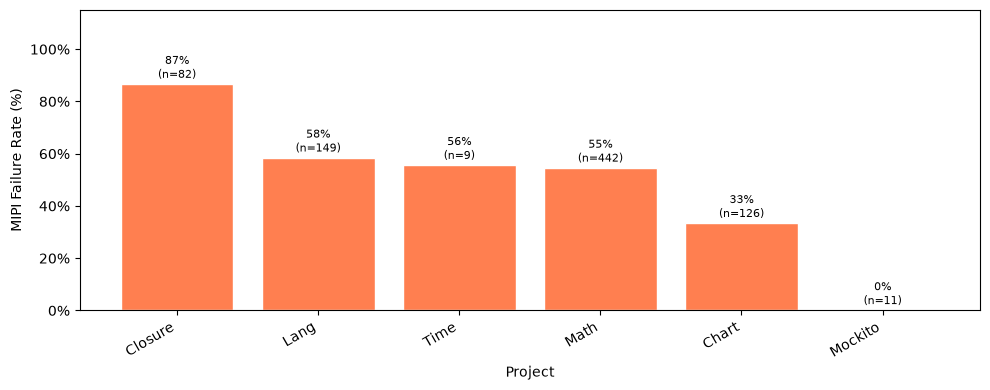

project  total  classified  failed  failure_rate
Closure     82          11      71     86.585366
   Lang    149          62      87     58.389262
   Time      9           4       5     55.555556
   Math    442         201     241     54.524887
  Chart    126          84      42     33.333333
Mockito     11          11       0      0.000000


In [16]:
# Failure rate by Defects4J project
project_stats = tool_failure_bar(df_all_patches, 'project', 'coral', figsize=(10, 4), save_name='mipi_failure_by_project')

### By Exception Type (for exception types with 10 or more patches)

Looking at exceptions with 10 or more patches:
Chi-square test (first_exception): χ²=188.75, df=9, p=7.5200823727e-36


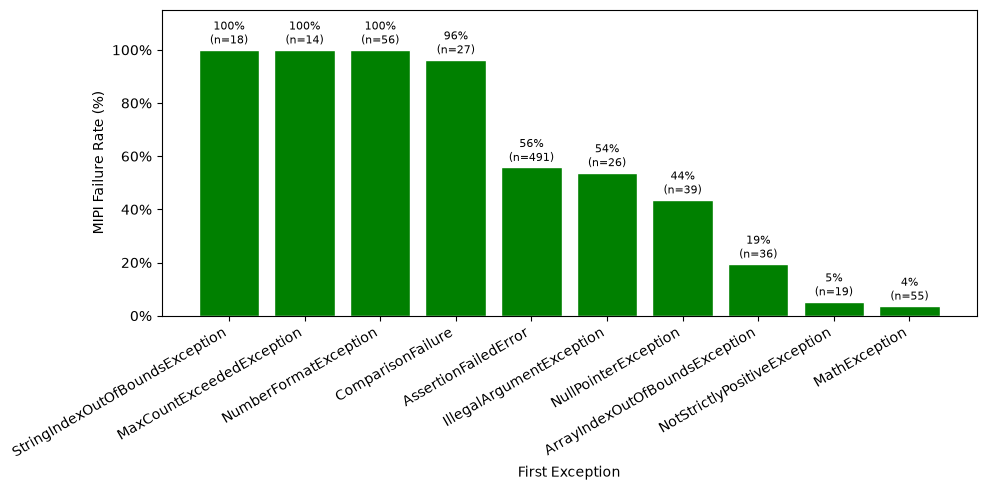

                first_exception  total  classified  failed  failure_rate
StringIndexOutOfBoundsException     18           0      18    100.000000
      MaxCountExceededException     14           0      14    100.000000
          NumberFormatException     56           0      56    100.000000
              ComparisonFailure     27           1      26     96.296296
           AssertionFailedError    491         217     274     55.804481
       IllegalArgumentException     26          12      14     53.846154
           NullPointerException     39          22      17     43.589744
 ArrayIndexOutOfBoundsException     36          29       7     19.444444
   NotStrictlyPositiveException     19          18       1      5.263158
                  MathException     55          53       2      3.636364


In [17]:
# List of exceptions with more than 10 occurrences
list_exceptions_with_10_or_more_occurrences = df_all_patches['first_exception'].value_counts()[df_all_patches['first_exception'].value_counts() > 10].index.tolist()

print("Looking at exceptions with 10 or more patches:")
exception_stats = tool_failure_bar(df_all_patches[df_all_patches['first_exception'].isin(list_exceptions_with_10_or_more_occurrences)], 'first_exception', 'green', figsize=(10, 5), save_name='mipi_failure_by_exception')

In [18]:
exception_stats = exception_stats.reset_index(drop=True)
df_all_patches['defects4j_bug'] = df_all_patches["project"].astype(str) + df_all_patches["bug_id"].astype(str)

bugs_by_exception = (
    df_all_patches.groupby('first_exception')['defects4j_bug']
    .agg(lambda bugs: sorted(bugs.dropna().astype(str).unique().tolist()))
)
exception_stats['bug_list'] = exception_stats['first_exception'].map(bugs_by_exception)

exception_stats

,first_exception,classified,total,failed,failure_rate,bug_list
0,StringIndexOutOfBoundsException,0,18,18,100.000000,"[Lang44, Lang45, Lang51, Lang6, Math101]"
1,MaxCountExceededException,0,14,14,100.000000,[Math28]
2,NumberFormatException,0,56,56,100.000000,[Lang58]
3,ComparisonFailure,1,27,26,96.296296,"[Closure62, Closure73, Lang46, Lang63]"
4,AssertionFailedError,217,491,274,55.804481,"[Chart1, Chart11, Chart12, Chart15, Chart20, Chart25, Chart26, Chart7, Chart8, Closure10, Closure115, Closure126, Closure129, Closure13, Closure14, Closure21, Closure22, Closure46, Closure48, Closure57, Closure86, Lang10, Lang55, Math105, Math11, Math15, Math2, Math20, Math30, Math33, Math34, Math41, Math42, Math5, Math50, Math53, Math57, Math59, Math6, Math62, Math63, Math64, Math65, Math69, Math7, Math71, Math73, Math75, Math80, Math82, Math84, Math88, Math96, Time11]"
5,IllegalArgumentException,12,26,14,53.846154,"[Chart13, Chart17, Chart24, Chart9, Closure19, Math95, Math97]"
6,NullPointerException,22,39,17,43.589744,"[Chart4, Closure2, Lang33, Lang57, Math70, Math79, Mockito38]"
7,ArrayIndexOutOfBoundsException,29,36,7,19.444444,"[Lang59, Math81]"
8,NotStrictlyPositiveException,18,19,1,5.263158,[Math58]
9,MathException,53,55,2,3.636364,[Math85]


In [19]:
df_all_patches.groupby('first_exception')['project'].value_counts()

first_exception                  project
ArrayIndexOutOfBoundsException   Lang        29
                                 Math         7
ArrayStoreException              Math         5
AssertionFailedError             Math       316
                                 Chart       95
                                 Closure     56
                                 Lang        23
                                 Time         1
ClassCastException               Math         5
ComparisonFailure                Closure     22
                                 Lang         5
Exception                        Mockito      7
IllegalArgumentException         Chart       20
                                 Math         5
                                 Closure      1
IllegalFieldValueException       Time         8
IndexOutOfBoundsException        Chart        5
MathException                    Math        55
MathRuntimeException$6           Math         4
MaxCountExceededException        Math        14

### By Repair Pattern

Chi-square test (repair pattern): χ²=265.97, df=21, p=2.5045e-44



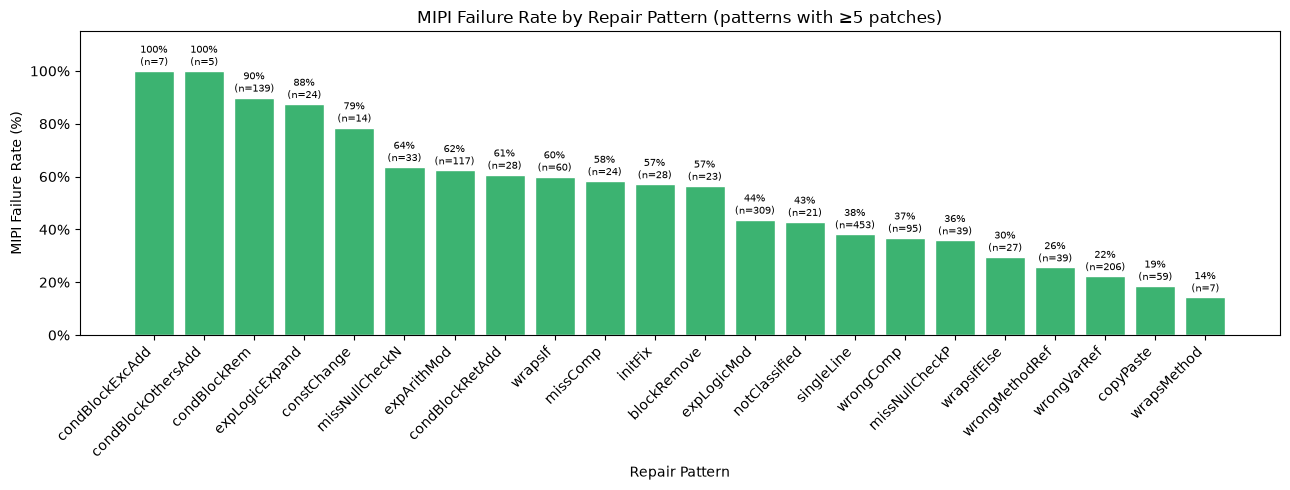

    repair_pattern  total  classified  failed  failure_rate
   condBlockExcAdd      7           0       7    100.000000
condBlockOthersAdd      5           0       5    100.000000
      condBlockRem    139          14     125     89.928058
    expLogicExpand     24           3      21     87.500000
       constChange     14           3      11     78.571429
    missNullCheckN     33          12      21     63.636364
       expArithMod    117          44      73     62.393162
   condBlockRetAdd     28          11      17     60.714286
           wrapsIf     60          24      36     60.000000
          missComp     24          10      14     58.333333
           initFix     28          12      16     57.142857
       blockRemove     23          10      13     56.521739
       expLogicMod    309         174     135     43.689320
     notClassified     21          12       9     42.857143
        singleLine    453         280     173     38.189845
         wrongComp     95          60   

In [20]:
### Failure rate by repair pattern (bug type)
# Each bug has one or more repair patterns from the RepairPatterns taxonomy.
# We join patch metadata to the bug's patterns to see if certain bug types cause more MIPI failures.

df_patterns = df_all_patches.dropna(subset=['repair_patterns']).copy()
df_patterns = (
    df_patterns.explode('repair_patterns')
    .rename(columns={'repair_patterns': 'repair_pattern'})
    .reset_index(drop=True)
)
df_patterns = df_patterns[df_patterns['repair_pattern'].notna() & (df_patterns['repair_pattern'] != '')]

pattern_stats = (
    df_patterns.groupby('repair_pattern')['mipi_classified']
    .agg(classified='sum', total='count')
    .reset_index()
)
pattern_stats['failed'] = pattern_stats['total'] - pattern_stats['classified']
pattern_stats['failure_rate'] = pattern_stats['failed'] / pattern_stats['total'] * 100
pattern_stats = pattern_stats[pattern_stats['total'] >= 5].sort_values('failure_rate', ascending=False)

contingency_pat = pd.crosstab(
    df_patterns[df_patterns['repair_pattern'].isin(pattern_stats['repair_pattern'])]['repair_pattern'],
    df_patterns[df_patterns['repair_pattern'].isin(pattern_stats['repair_pattern'])]['mipi_classified']
)
chi2, p_pat, dof, _ = stats.chi2_contingency(contingency_pat)
print(f"Chi-square test (repair pattern): χ²={chi2:.2f}, df={dof}, p={p_pat:.4e}\n")

fig, ax = plt.subplots(figsize=(13, 5))
bars = ax.bar(pattern_stats['repair_pattern'], pattern_stats['failure_rate'],
              color='mediumseagreen', edgecolor='white')
ax.set_ylabel('MIPI Failure Rate (%)')
ax.set_xlabel('Repair Pattern')
ax.set_title('MIPI Failure Rate by Repair Pattern (patterns with ≥5 patches)')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0, 115)
for bar, row in zip(bars, pattern_stats.itertuples()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
            f'{row.failure_rate:.0f}%\n(n={row.total})',
            ha='center', va='bottom', fontsize=7)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
fig.savefig(FIGURES_DIR / f"mipi_failure_by_repair_pattern_{dataset_dir_name}.png", dpi=300)
plt.show()

print(pattern_stats[['repair_pattern', 'total', 'classified', 'failed', 'failure_rate']].to_string(index=False))

### By Patch Size

Patch complexity comparison (MIPI classified vs. failed patches):

                             Metric  Classified median  Failed median  Mann-Whitney U  p-value  Significant (p<0.05)
Total Patch Lines (Added + Removed)                2.0            3.0         80928.0 0.479487                 False
             Deviation from Dev Fix                0.0            0.0         93188.0 0.002517                  True


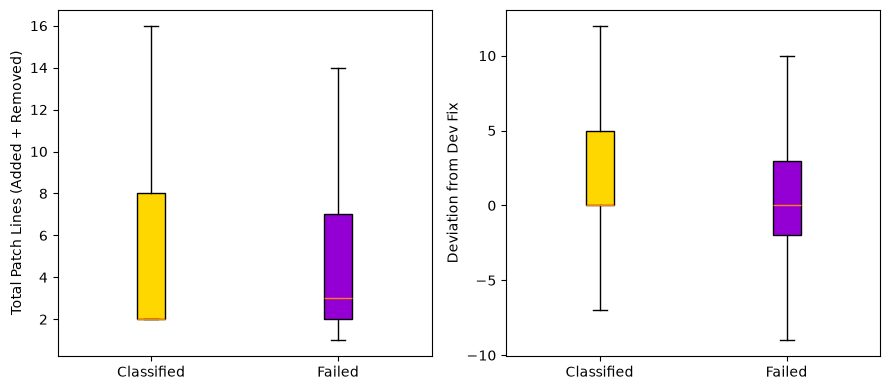

In [21]:
### Patch complexity analysis: MIPI classified vs. failed patches
# Compare patch size and change metrics between patches MIPI classified
# and patches it failed to classify.

from scipy.stats import mannwhitneyu

complexity_cols = {
    # 'patch_added_lines': 'Added Lines',
    # 'patch_removed_lines': 'Removed Lines',
    'patch_total_lines': 'Total Patch Lines (Added + Removed)',
    'deviation_from_dev_patch': 'Deviation from Dev Fix',
    # 'patch_net_change': 'Net Change (Added - Removed)',
}

complexity_metrics = list(complexity_cols)
df_cx = df_all_patches.dropna(subset=complexity_metrics)
grp_ok = df_cx[df_cx['mipi_classified']]
grp_bad = df_cx[~df_cx['mipi_classified']]

results = []
for col, label in complexity_cols.items():
    u, p = mannwhitneyu(grp_ok[col], grp_bad[col], alternative='two-sided')
    results.append({
        'Metric': label,
        'Classified median': grp_ok[col].median(),
        'Failed median': grp_bad[col].median(),
        'Mann-Whitney U': u,
        'p-value': p,
        'Significant (p<0.05)': p < 0.05,
    })

df_cx_results = pd.DataFrame(results)
print("Patch complexity comparison (MIPI classified vs. failed patches):\n")
print(df_cx_results.to_string(index=False))

fig, axes = plt.subplots(
    1,
    len(complexity_cols),
    figsize=(max(4, 4.5 * len(complexity_cols)), 4),
    squeeze=False,
)
for ax, (col, label) in zip(axes[0], complexity_cols.items()):
    data = [grp_ok[col].values, grp_bad[col].values]
    bp = ax.boxplot(data, showfliers=False, patch_artist=True)
    ax.set_xticklabels(['Classified', 'Failed'])
    ax.set_ylabel(label)
    bp['boxes'][0].set_facecolor('gold')
    bp['boxes'][1].set_facecolor('darkviolet')
    ax.ticklabel_format(axis='y', style='plain', useOffset=False)

plt.tight_layout()
fig.savefig(FIGURES_DIR / f"mipi_patch_complexity_comparison_{dataset_dir_name}.png", dpi=300)
plt.show()

## APR tool x Defects4J Project Heatmap

In [22]:
# Load Repairllama Dataset just for the heatmap figure
df_rep_total_classified_patches_llm4patchcorrect = pd.read_csv(Path(f"../results/LLM4PatchCorrectness/repairllama_deduplicated.csv"))
df_rep_mipi_classified_patches = pd.read_csv(Path(f"../results/mipi/repairllama_deduplicated.csv"))
list_rep_mipi_patches = df_rep_mipi_classified_patches['patch_name'].tolist()

print("Total classified patches from LLM4PatchCorrectness:", len(df_rep_total_classified_patches_llm4patchcorrect))
print("Total classified patches from MIPI:", len(df_rep_mipi_classified_patches))


df_rep_all_patches = df_rep_total_classified_patches_llm4patchcorrect[['patch_name', 'correctness']].copy()
df_rep_all_patches['project'] = df_rep_all_patches['patch_name'].apply(lambda x: x.split('_')[0])
df_rep_all_patches['bug_id'] = df_rep_all_patches['patch_name'].apply(lambda x: x.split('_')[1])
df_rep_all_patches['apr_tool'] = df_rep_all_patches['patch_name'].apply(
    lambda x: TOOL_NAME_MAP.get(x.split('_')[2].lower(), x.split('_')[2])
)
df_rep_all_patches['mipi_classified'] = df_rep_all_patches['patch_name'].isin(list_rep_mipi_patches)
df_rep_all_patches['mipi_prediction'] = df_rep_all_patches['patch_name'].apply(
    lambda x: df_rep_mipi_classified_patches.loc[
        df_rep_mipi_classified_patches['patch_name'] == x, 'prediction'
    ].values[0] if x in list_rep_mipi_patches else None
)

# Combine df_rep_all_patches with df_all_patches into df_combined_all_patches
df_combined_all_patches = pd.concat([df_all_patches, df_rep_all_patches], ignore_index=True)
df_combined_all_patches['apr_tool'].value_counts()

Total classified patches from LLM4PatchCorrectness: 157
Total classified patches from MIPI: 111


apr_tool
TBar           211
Repairllama    157
Avatar         133
kPAR           114
jGenProg        80
dynamoth        72
Nopol           57
SimFix          51
jKali           41
FixMiner        36
jMutRepair      24
Name: count, dtype: int64

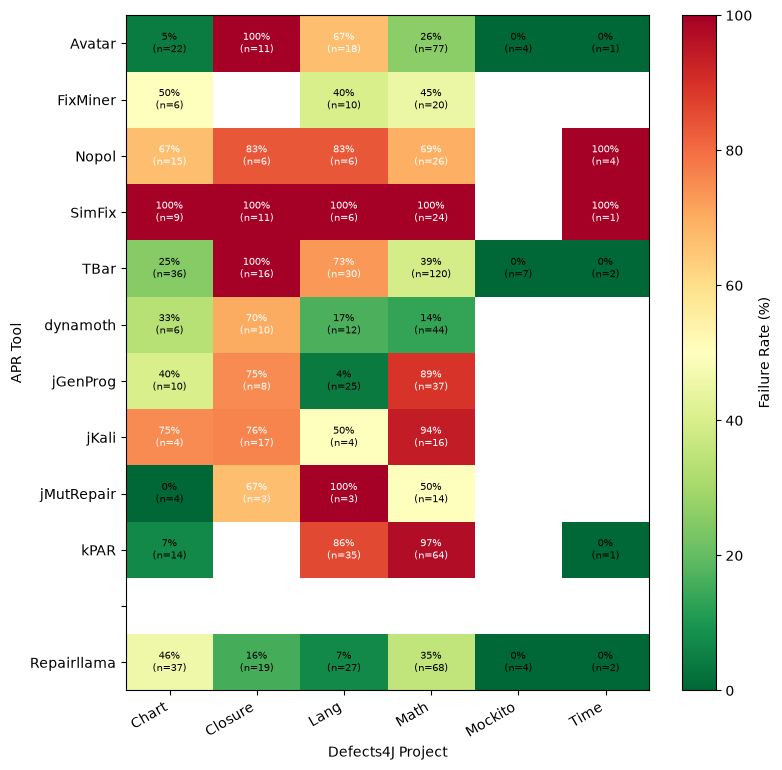

In [23]:
### Tool × Project failure rate heatmap

pivot = (
    df_combined_all_patches.groupby(['apr_tool', 'project'])['mipi_classified']
    .agg(failed=lambda x: (~x).sum(), total='count')
    .reset_index()
)
pivot['failure_rate'] = pivot['failed'] / pivot['total'] * 100
heatmap_data = pivot.pivot_table(index='apr_tool', columns='project', values='failure_rate')
heatmap_counts = pivot.pivot_table(index='apr_tool', columns='project', values='total')

tool_order = [tool for tool in heatmap_data.index if tool != 'Repairllama']
if 'Repairllama' in heatmap_data.index:
    tool_order.append('Repairllama')
heatmap_data = heatmap_data.reindex(tool_order)
heatmap_counts = heatmap_counts.reindex(tool_order)

heatmap_values = heatmap_data.to_numpy(dtype=float)
heatmap_count_values = heatmap_counts.to_numpy(dtype=float)
heatmap_labels = list(heatmap_data.index)
if 'Repairllama' in heatmap_data.index:
    repairllama_row = heatmap_labels.index('Repairllama')
    gap = np.full((1, heatmap_values.shape[1]), np.nan)
    heatmap_values = np.vstack((heatmap_values[:repairllama_row], gap, heatmap_values[repairllama_row:]))
    heatmap_count_values = np.vstack((heatmap_count_values[:repairllama_row], gap, heatmap_count_values[repairllama_row:]))
    heatmap_labels.insert(repairllama_row, '')

fig, ax = plt.subplots(figsize=(max(8, len(heatmap_data.columns) * 0.9), max(4, len(heatmap_labels) * 0.65)))
im = ax.imshow(heatmap_values, cmap='RdYlGn_r', vmin=0, vmax=100, aspect='auto')

ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns, rotation=30, ha='right')
ax.set_yticks(range(len(heatmap_labels)))
ax.set_yticklabels(heatmap_labels)
ax.set_xlabel('Defects4J Project')
ax.set_ylabel('APR Tool')
# ax.set_title('MIPI Failure Rate (%) by APR Tool and Project')

for i in range(len(heatmap_labels)):
    for j in range(len(heatmap_data.columns)):
        val = heatmap_values[i, j]
        if not np.isnan(val):
            n = int(heatmap_count_values[i, j])
            text_color = 'white' if val > 60 else 'black'
            ax.text(j, i, f'{val:.0f}%\n(n={n})', ha='center', va='center',
                    fontsize=7, color=text_color)

plt.colorbar(im, ax=ax, label='Failure Rate (%)')
plt.tight_layout()
fig.savefig(FIGURES_DIR / f"mipi_failure_heatmap_tool_project_{dataset_dir_name}.png", dpi=400)
plt.show()

### Patch Size and Change Metrics

Complexity comparison (MIPI classified vs. failed patches):

               Metric  Classified median  Failed median  Mann-Whitney U      p-value  Significant (p<0.05)
dev_fix_size_in_lines                2.0            3.0         57624.0 2.674650e-17                  True
      dev_fix_n_files                1.0            1.0         83252.0 8.586609e-01                 False
     dev_fix_n_chunks                1.0            1.0         81703.5 5.458399e-01                 False


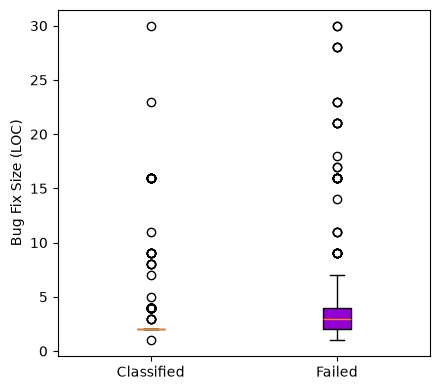

In [24]:
### Complexity analysis: do patches MIPI fails on target more complex bugs?
# Using Mann-Whitney U (non-parametric) to compare complexity metrics between
# patches MIPI classified vs. those it failed on.

from scipy.stats import mannwhitneyu

complexity_cols = {
    'dev_fix_size_in_lines': 'Bug Fix Size (LOC)',
    'dev_fix_n_files': 'Files Changed',
    'dev_fix_n_chunks': 'Hunks',
}

df_cx = df_all_patches.dropna(subset=['dev_fix_size_in_lines'])
grp_ok  = df_cx[df_cx['mipi_classified']]
grp_bad = df_cx[~df_cx['mipi_classified']]

results = []
for col, label in complexity_cols.items():
    u, p = mannwhitneyu(grp_ok[col], grp_bad[col], alternative='two-sided')
    results.append({
        'Metric': col,
        'Classified median': grp_ok[col].median(),
        'Failed median':     grp_bad[col].median(),
        'Mann-Whitney U':    u,
        'p-value':           p,
        'Significant (p<0.05)': p < 0.05,
    })

df_cx_results = pd.DataFrame(results)
print("Complexity comparison (MIPI classified vs. failed patches):\n")
print(df_cx_results.to_string(index=False))

# Choose any non-empty subset of the three available metrics for the figure.
selected_metrics = [
    'dev_fix_size_in_lines',
    # 'dev_fix_n_files',
    # 'dev_fix_n_chunks'
]
selected_complexity_cols = {
    col: complexity_cols[col] for col in selected_metrics
}
if not selected_complexity_cols:
    raise ValueError('Select at least one metric for the complexity figure.')

fig, axes = plt.subplots(
    1,
    len(selected_complexity_cols),
    figsize=(max(4, 4.5 * len(selected_complexity_cols)), 4),
    squeeze=False,
)
for ax, (col, label) in zip(axes[0], selected_complexity_cols.items()):
    data = [grp_ok[col].dropna().values, grp_bad[col].dropna().values]
    bp = ax.boxplot(data, showfliers=True, patch_artist=True)
    ax.set_xticklabels(['Classified', 'Failed'])
    ax.set_ylabel(label)
    bp['boxes'][0].set_facecolor('gold')
    bp['boxes'][1].set_facecolor('darkviolet')
    # ax.set_title(label, fontsize=9)
    ax.ticklabel_format(axis='y', style='plain', useOffset=False)
# plt.suptitle('Bug Fix Complexity: Patches MIPI Classified vs. Failed (outliers hidden)', fontsize=10)
plt.tight_layout()
fig.savefig(FIGURES_DIR / f"mipi_complexity_comparison_{dataset_dir_name}.png", dpi=300)
plt.show()

## Summary table for paper

The table below consolidates per-tool MIPI failure statistics for easy inclusion in the paper.

In [25]:
summary = tool_stats[['apr_tool', 'total', 'classified', 'failed', 'failure_rate']].copy()
summary.columns = ['APR Tool', 'Total Patches', 'Classified', 'Failed', 'Failure Rate (%)']
summary['Failure Rate (%)'] = summary['Failure Rate (%)'].round(1)

overall_row = pd.DataFrame([{
    'APR Tool': 'Overall',
    'Total Patches': total,
    'Classified': n_classified,
    'Failed': n_failed,
    'Failure Rate (%)': round(n_failed / total * 100, 1),
}])
summary = pd.concat([summary, overall_row], ignore_index=True)

print(summary.to_string(index=False))
print()
print("LaTeX:")
print(summary.to_latex(index=False, float_format='%.1f'))

  APR Tool  Total Patches  Classified  Failed  Failure Rate (%)
    SimFix             51           0      51             100.0
      kPAR            114          21      93              81.6
     jKali             41           8      33              80.5
     Nopol             57          15      42              73.7
  jGenProg             80          36      44              55.0
jMutRepair             24          12      12              50.0
      TBar            211         117      94              44.5
  FixMiner             36          20      16              44.4
    Avatar            133          89      44              33.1
  dynamoth             72          55      17              23.6
   Overall             54         373     446             825.9

LaTeX:
\begin{tabular}{lrrrr}
\toprule
APR Tool & Total Patches & Classified & Failed & Failure Rate (%) \\
\midrule
SimFix & 51 & 0 & 51 & 100.0 \\
kPAR & 114 & 21 & 93 & 81.6 \\
jKali & 41 & 8 & 33 & 80.5 \\
Nopol & 57 & 15 & 42 

## Looking closer at Math-33, the bug with the most patches

In [26]:
most_common = (
    df_all_patches.groupby(["project", "bug_id"])
    .size()
    .sort_values(ascending=False)
)

most_common

project  bug_id
Math     33        100
         50         82
Lang     58         56
Math     85         55
         80         48
Chart    7          38
Lang     59         29
Chart    1          29
Math     82         22
Closure  126        21
         62         20
Math     58         19
         28         14
Closure  46         14
Chart    25         13
Lang     55         13
         51         11
Chart    9          11
Math     30         10
Lang     57         10
         10         10
Time     7           8
Math     70          7
Mockito  29          7
Math     81          7
Chart    4           6
         13          5
Closure  21          5
Math     8           5
Lang     33          5
Chart    15          4
         5           4
Math     95          4
         79          4
         57          4
         62          4
         49          4
Mockito  38          4
Math     63          4
Closure  57          4
Lang     63          4
         43          4
         44       

In [27]:
math_33_patches_df = df_all_patches[(df_all_patches['project'] == 'Math') & (df_all_patches['bug_id'] == '33')].reset_index(drop=True)
math_33_patches_df[['patch_name', 'correctness', 'mipi_classified', 'apr_tool', 'dev_fix_lines_add', 'dev_fix_lines_rem', 'dev_fix_lines_mod', 'first_exception', 'patch_added_lines', 'patch_removed_lines']].head(30)

,patch_name,correctness,mipi_classified,apr_tool,dev_fix_lines_add,dev_fix_lines_rem,dev_fix_lines_mod,first_exception,patch_added_lines,patch_removed_lines
0,Math_33_kPAR_Patch_568058_71_cp4.diff,overfitting,False,kPAR,0,0,1,AssertionFailedError,5,46
1,Math_33_Avatar_Patch_19269874_961.diff,overfitting,True,Avatar,0,0,1,AssertionFailedError,5,46
2,Math_33_Avatar_Patch_17877320_912.diff,overfitting,True,Avatar,0,0,1,AssertionFailedError,5,46
3,Math_33_kPAR_Patch_4596778_252_cp97.diff,overfitting,False,kPAR,0,0,1,AssertionFailedError,1,1
4,Math_33_Nopol_patch_276314_4.diff,overfitting,False,Nopol,0,0,1,AssertionFailedError,6,4
5,Math_33_Avatar_Patch_17833553_911.diff,overfitting,True,Avatar,0,0,1,AssertionFailedError,5,46
6,Math_33_Avatar_Patch_18922173_944.diff,overfitting,True,Avatar,0,0,1,AssertionFailedError,2,46
7,Math_33_dynamoth_patch_252118_1.diff,overfitting,True,dynamoth,0,0,1,AssertionFailedError,5,3
8,Math_33_dynamoth_patch_4236237_20.diff,overfitting,True,dynamoth,0,0,1,AssertionFailedError,6,4
9,Math_33_dynamoth_patch_4236229_17.diff,overfitting,True,dynamoth,0,0,1,AssertionFailedError,6,4


In [28]:
math_33_patches_df['correctness'].value_counts()

correctness
overfitting    97
correct         3
Name: count, dtype: int64

In [29]:
math_33_patches_df['mipi_classified'].value_counts()

mipi_classified
True     72
False    28
Name: count, dtype: int64

In [30]:
math_33_patches_df[math_33_patches_df['mipi_classified'] == True]['apr_tool'].value_counts()

apr_tool
Avatar      51
dynamoth    20
kPAR         1
Name: count, dtype: int64

In [31]:
math_33_patches_df[math_33_patches_df['mipi_classified'] == False]['apr_tool'].value_counts()

apr_tool
kPAR      11
Avatar    10
Nopol      4
SimFix     3
Name: count, dtype: int64

In [32]:
math_33_patches_df[math_33_patches_df['apr_tool'] == "Avatar"].head(61)

,patch_name,correctness,project,bug_id,apr_tool,mipi_classified,mipi_prediction,repair_patterns,dev_fix_lines_add,dev_fix_lines_rem,dev_fix_lines_mod,dev_fix_n_files,dev_fix_n_chunks,first_exception,dev_fix_size_in_lines,patch_added_lines,patch_removed_lines,patch_total_lines,patch_net_change,deviation_from_dev_patch,patch_shape,patch_size_bin,defects4j_bug
1,Math_33_Avatar_Patch_19269874_961.diff,overfitting,Math,33,Avatar,True,correct,"[expLogicMod, singleLine, wrongVarRef]",0,0,1,1,1,AssertionFailedError,2,5,46,51,-41,49,deletion-heavy,50+,Math33
2,Math_33_Avatar_Patch_17877320_912.diff,overfitting,Math,33,Avatar,True,overfitting,"[expLogicMod, singleLine, wrongVarRef]",0,0,1,1,1,AssertionFailedError,2,5,46,51,-41,49,deletion-heavy,50+,Math33
5,Math_33_Avatar_Patch_17833553_911.diff,overfitting,Math,33,Avatar,True,overfitting,"[expLogicMod, singleLine, wrongVarRef]",0,0,1,1,1,AssertionFailedError,2,5,46,51,-41,49,deletion-heavy,50+,Math33
6,Math_33_Avatar_Patch_18922173_944.diff,overfitting,Math,33,Avatar,True,correct,"[expLogicMod, singleLine, wrongVarRef]",0,0,1,1,1,AssertionFailedError,2,2,46,48,-44,46,deletion-heavy,26-50,Math33
10,Math_33_Avatar_Patch_18487889_934.diff,overfitting,Math,33,Avatar,True,correct,"[expLogicMod, singleLine, wrongVarRef]",0,0,1,1,1,AssertionFailedError,2,2,46,48,-44,46,deletion-heavy,26-50,Math33
12,Math_33_Avatar_Patch_18531935_935.diff,overfitting,Math,33,Avatar,True,correct,"[expLogicMod, singleLine, wrongVarRef]",0,0,1,1,1,AssertionFailedError,2,2,46,48,-44,46,deletion-heavy,26-50,Math33
13,Math_33_Avatar_Patch_18966020_945.diff,overfitting,Math,33,Avatar,True,correct,"[expLogicMod, singleLine, wrongVarRef]",0,0,1,1,1,AssertionFailedError,2,2,46,48,-44,46,deletion-heavy,26-50,Math33
14,Math_33_Avatar_Patch_19656960_971.diff,overfitting,Math,33,Avatar,True,correct,"[expLogicMod, singleLine, wrongVarRef]",0,0,1,1,1,AssertionFailedError,2,2,46,48,-44,46,deletion-heavy,26-50,Math33
15,Math_33_Avatar_Patch_21301754_1066.diff,overfitting,Math,33,Avatar,False,None,"[expLogicMod, singleLine, wrongVarRef]",0,0,1,1,1,AssertionFailedError,2,2,46,48,-44,46,deletion-heavy,26-50,Math33
17,Math_33_Avatar_Patch_21520957_1071.diff,overfitting,Math,33,Avatar,False,None,"[expLogicMod, singleLine, wrongVarRef]",0,0,1,1,1,AssertionFailedError,2,2,46,48,-44,46,deletion-heavy,26-50,Math33
